# Preprocess

## Double Check Data

In [ ]:
import pandas as pd

current_processed = pd.read_csv("current_processed.csv")
previous_processed = pd.read_csv("previous_processed.csv")
data_merged = pd.read_csv("final_df.csv")

In [1]:
import pandas as pd
data_merged = pd.read_csv("final_df.csv")

In [2]:
print(data_merged.shape)
print(data_merged.head())
print(data_merged.columns[:20])

(307511, 308)
  NAME_CONTRACT_TYPE CODE_GENDER  FLAG_OWN_CAR  FLAG_OWN_REALTY  CNT_CHILDREN  \
0         Cash loans           M           0.0              1.0           0.0   
1         Cash loans           F           0.0              0.0           0.0   
2    Revolving loans           M           1.0              1.0           0.0   
3         Cash loans           F           0.0              1.0           0.0   
4         Cash loans           M           0.0              1.0           0.0   

   AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE NAME_TYPE_SUITE  \
0          202500.0    406597.5      24700.5         351000.0   Unaccompanied   
1          270000.0   1293502.5      35698.5        1129500.0          Family   
2           67500.0    135000.0       6750.0         135000.0   Unaccompanied   
3          135000.0    312682.5      29686.5         297000.0   Unaccompanied   
4          121500.0    513000.0      21865.5         513000.0   Unaccompanied   

   ... prev_

In [3]:
print(data_merged.shape)

print("SK_ID_CURR" in data_merged.columns)
print("TARGET" in data_merged.columns)

print(data_merged[["SK_ID_CURR", "TARGET"]].head())
print(data_merged["TARGET"].value_counts(normalize=True))

(307511, 308)
True
True
   SK_ID_CURR  TARGET
0      100002       1
1      100003       0
2      100004       0
3      100006       0
4      100007       0
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


In [6]:
print(data_merged["SK_ID_CURR"].is_unique)
print(data_merged["SK_ID_CURR"].duplicated().sum())

True
0


# Train and Test Set

X: 数据本体
Y: target

In [4]:
y = data_merged["TARGET"].copy()

X = data_merged.drop(columns=["SK_ID_CURR", "TARGET"]).copy()

print(X.shape)
print(y.shape)
print(y.value_counts(normalize=True))

(307511, 306)
(307511,)
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


In [5]:
num_cols = X.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns
bool_cols = X.select_dtypes(include=["bool"]).columns

print("Numerical columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))
print("Bool columns:", len(bool_cols))

Numerical columns: 279
Categorical columns: 27
Bool columns: 0


convert bool to 0/1

In [9]:
bool_cols = X.select_dtypes(include=["bool"]).columns

X[bool_cols] = X[bool_cols].astype(int)

num_cols = X.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns
bool_cols = X.select_dtypes(include=["bool"]).columns

print("Numerical columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))
print("Bool columns:", len(bool_cols))
print("Total:", len(num_cols) + len(cat_cols) + len(bool_cols))

Numerical columns: 279
Categorical columns: 27
Bool columns: 0
Total: 306


## Split

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(246008, 306)
(61503, 306)
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64
TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64


In [7]:
num_cols = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns

cat_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns

print("Numerical columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))
print("Total:", len(num_cols) + len(cat_cols))

Numerical columns: 279
Categorical columns: 27
Total: 306


In [12]:
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

0
0


OrdinalEncoder + StandardScaler

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape)
print(X_test_processed.shape)
print(type(X_train_processed))

(246008, 306)
(61503, 306)
<class 'numpy.ndarray'>


In [9]:
from sklearn.preprocessing import StandardScaler

final_scaler = StandardScaler()

X_train_ae = final_scaler.fit_transform(X_train_processed)
X_test_ae = final_scaler.transform(X_test_processed)

print(X_train_ae.shape)
print(X_test_ae.shape)
print(X_train_ae.mean().round(4))
print(X_train_ae.std().round(4))

(246008, 306)
(61503, 306)
-0.0
1.0


temp save

In [15]:
import joblib

joblib.dump(X_train_ae, "X_train_ae.pkl")
joblib.dump(X_test_ae, "X_test_ae.pkl")
joblib.dump(y_train, "y_train.pkl")
joblib.dump(y_test, "y_test.pkl")
joblib.dump(preprocessor, "ordinal_preprocessor.pkl")
joblib.dump(final_scaler, "final_scaler.pkl")

['final_scaler.pkl']

# Autoencoder

In [42]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 转成 float32 tensor
X_train_tensor = torch.tensor(X_train_ae, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_ae, dtype=torch.float32)

# autoencoder 的 input 和 target 都是 X 自己
train_dataset = TensorDataset(X_train_tensor, X_train_tensor)
test_dataset = TensorDataset(X_test_tensor, X_test_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=512,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=512,
    shuffle=False
)

print(X_train_tensor.shape)
print(X_test_tensor.shape)

Device: cpu
torch.Size([246008, 306])
torch.Size([61503, 306])


In [43]:
import torch
import torch.nn as nn

input_dim = X_train_ae.shape[1]   # should be 239
latent_dim = 100

class Autoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super(Autoencoder, self).__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.LazyLinear(64),
            nn.ReLU(),
            nn.Linear(64, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, input_dim)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        reconstructed = self.decoder(encoded)
        return reconstructed
    
model = Autoencoder(input_dim, latent_dim).to(device)

print(model)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=306, out_features=128, bias=True)
    (1): ReLU()
    (2): LazyLinear(in_features=0, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=100, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=100, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=306, bias=True)
  )
)


In [44]:
import torch.optim as optim
import matplotlib.pyplot as plt

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)

num_epochs = 30

train_losses = []
val_losses = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_n = 0
    
    for X_batch, _ in train_loader:
        X_batch = X_batch.to(device)
        
        optimizer.zero_grad()
        
        reconstructed = model(X_batch)
        loss = criterion(reconstructed, X_batch)
        
        loss.backward()
        optimizer.step()
        
        batch_size = X_batch.size(0)
        train_loss += loss.item() * batch_size
        train_n += batch_size
    
    train_loss = train_loss / train_n
    train_losses.append(train_loss)
    
    model.eval()
    val_loss = 0
    val_n = 0
    
    with torch.no_grad():
        for X_batch, _ in test_loader:
            X_batch = X_batch.to(device)
            
            reconstructed = model(X_batch)
            loss = criterion(reconstructed, X_batch)
            
            batch_size = X_batch.size(0)
            val_loss += loss.item() * batch_size
            val_n += batch_size
    
    val_loss = val_loss / val_n
    val_losses.append(val_loss)
    
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch 1/30 | Train Loss: 0.4431 | Val Loss: 0.3036
Epoch 2/30 | Train Loss: 0.2729 | Val Loss: 0.2438
Epoch 3/30 | Train Loss: 0.2334 | Val Loss: 0.2163
Epoch 4/30 | Train Loss: 0.2129 | Val Loss: 0.2005
Epoch 5/30 | Train Loss: 0.1999 | Val Loss: 0.1887
Epoch 6/30 | Train Loss: 0.1881 | Val Loss: 0.1769
Epoch 7/30 | Train Loss: 0.1781 | Val Loss: 0.1684
Epoch 8/30 | Train Loss: 0.1700 | Val Loss: 0.1606
Epoch 9/30 | Train Loss: 0.1633 | Val Loss: 0.1542
Epoch 10/30 | Train Loss: 0.1575 | Val Loss: 0.1486
Epoch 11/30 | Train Loss: 0.1536 | Val Loss: 0.1451
Epoch 12/30 | Train Loss: 0.1487 | Val Loss: 0.1427
Epoch 13/30 | Train Loss: 0.1452 | Val Loss: 0.1391
Epoch 14/30 | Train Loss: 0.1415 | Val Loss: 0.1365
Epoch 15/30 | Train Loss: 0.1390 | Val Loss: 0.1345
Epoch 16/30 | Train Loss: 0.1350 | Val Loss: 0.1311
Epoch 17/30 | Train Loss: 0.1327 | Val Loss: 0.1284
Epoch 18/30 | Train Loss: 0.1293 | Val Loss: 0.1263
Epoch 19/30 | Train Loss: 0.1271 | Val Loss: 0.1237
Epoch 20/30 | Train L

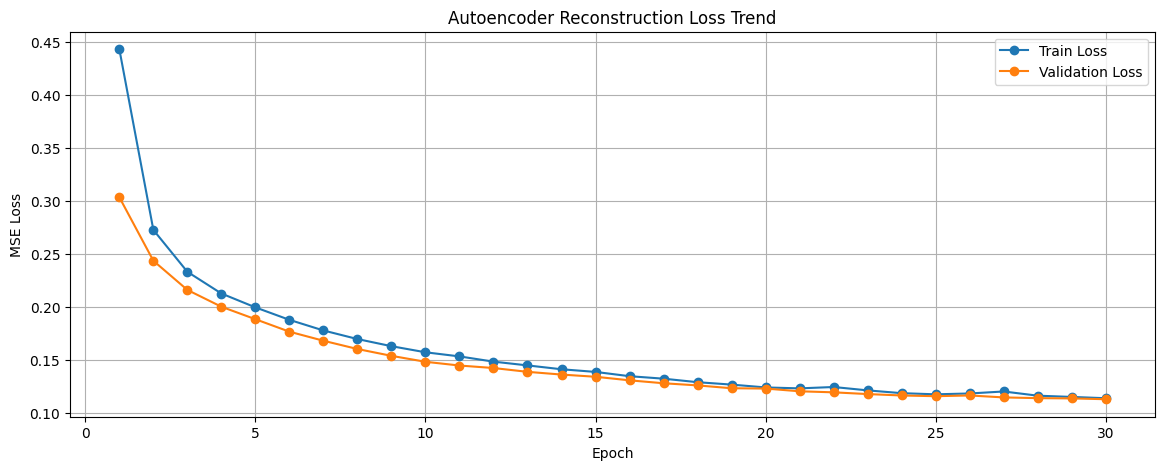

In [45]:
plt.figure(figsize=(14, 5))

plt.plot(range(1, num_epochs + 1), train_losses, marker='o', label='Train Loss')
plt.plot(range(1, num_epochs + 1), val_losses, marker='o', label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Reconstruction Loss Trend")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
model.eval()

with torch.no_grad():
    X_train_tensor = torch.tensor(X_train_ae, dtype=torch.float32).to(device)
    X_test_tensor = torch.tensor(X_test_ae, dtype=torch.float32).to(device)

    encoded_train = model.encoder(X_train_tensor).cpu().numpy()
    encoded_test = model.encoder(X_test_tensor).cpu().numpy()

print(encoded_train.shape)
print(encoded_test.shape)

(246008, 100)
(61503, 100)


In [ ]:
# =========================
# Sanity check: encoded features + Logistic Regression
# =========================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

lr_encoded = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    n_jobs=-1
)

lr_encoded.fit(encoded_train, y_train)

proba_lr = lr_encoded.predict_proba(encoded_test)[:, 1]
pred_lr = (proba_lr >= 0.5).astype(int)

print("Encoded Logistic ROC AUC:", roc_auc_score(y_test, proba_lr))
print(confusion_matrix(y_test, pred_lr))
print(classification_report(y_test, pred_lr))

Encoded Logistic ROC AUC: 0.7465795785753733
[[38500 18038]
 [ 1594  3371]]
              precision    recall  f1-score   support

           0       0.96      0.68      0.80     56538
           1       0.16      0.68      0.26      4965

    accuracy                           0.68     61503
   macro avg       0.56      0.68      0.53     61503
weighted avg       0.90      0.68      0.75     61503



In [15]:
model.eval()

with torch.no_grad():
    # Use the same tensors created above
    reconstructed_train = model.decoder(torch.tensor(encoded_train, dtype=torch.float32).to(device))
    reconstructed_test = model.decoder(torch.tensor(encoded_test, dtype=torch.float32).to(device))

    X_train_original = X_train_tensor.cpu()
    X_test_original = X_test_tensor.cpu()

    reconstructed_train = reconstructed_train.cpu()
    reconstructed_test = reconstructed_test.cpu()

# Overall reconstruction R² for train set
train_sse = torch.sum((X_train_original - reconstructed_train) ** 2)
train_sst = torch.sum((X_train_original - torch.mean(X_train_original, dim=0)) ** 2)
train_reconstruction_r2 = 1 - train_sse / train_sst

# Overall reconstruction R² for test set
test_sse = torch.sum((X_test_original - reconstructed_test) ** 2)
test_sst = torch.sum((X_test_original - torch.mean(X_test_original, dim=0)) ** 2)
test_reconstruction_r2 = 1 - test_sse / test_sst

print("Train reconstruction R²:", train_reconstruction_r2.item())
print("Test reconstruction R²:", test_reconstruction_r2.item())

print("Train preserved information (%):", train_reconstruction_r2.item() * 100)
print("Test preserved information (%):", test_reconstruction_r2.item() * 100)

Train reconstruction R²: 0.8849085569381714
Test reconstruction R²: 0.8850917220115662
Train preserved information (%): 88.49085569381714
Test preserved information (%): 88.50917220115662


# CNN

In [16]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# encoded features -> tensor
X_train_cnn = torch.tensor(encoded_train, dtype=torch.float32).unsqueeze(1)
X_test_cnn = torch.tensor(encoded_test, dtype=torch.float32).unsqueeze(1)

# labels -> tensor
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32)

print(X_train_cnn.shape)
print(X_test_cnn.shape)
print(y_train_tensor.shape)
print(y_test_tensor.shape)

torch.Size([246008, 1, 100])
torch.Size([61503, 1, 100])
torch.Size([246008])
torch.Size([61503])


In [17]:
train_dataset_cnn = TensorDataset(X_train_cnn, y_train_tensor)
test_dataset_cnn = TensorDataset(X_test_cnn, y_test_tensor)

train_loader_cnn = DataLoader(
    train_dataset_cnn,
    batch_size=512,
    shuffle=True
)

test_loader_cnn = DataLoader(
    test_dataset_cnn,
    batch_size=512,
    shuffle=False
)

In [18]:
class CNNClassifierV3(nn.Module):
    def __init__(self):
        super(CNNClassifierV3, self).__init__()
        
        self.conv = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),   # 50 -> 25
            
            nn.Conv1d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),   # 25 -> 12
        )
        
        self.fc = nn.Sequential(
            nn.LazyLinear(64),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(64, 1)
        )
        
    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x.squeeze(1)

cnn_model = CNNClassifierV3().to(device)
print(cnn_model)

CNNClassifierV3(
  (conv): Sequential(
    (0): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): LazyLinear(in_features=0, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [19]:
import torch.optim as optim
import matplotlib.pyplot as plt

# class imbalance weight
num_pos = (y_train_tensor == 1).sum()
num_neg = (y_train_tensor == 0).sum()
pos_weight = torch.tensor(5.0).to(device)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight.to(device)
)

optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

num_epochs = 30

# 用来存每个 epoch 的 loss
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    cnn_model.train()
    train_loss = 0
    
    for X_batch, y_batch in train_loader_cnn:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        optimizer.zero_grad()
        
        logits = cnn_model(X_batch)
        loss = criterion(logits, y_batch)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
    
    train_loss = train_loss / len(train_loader_cnn)
    train_losses.append(train_loss)
    
    cnn_model.eval()
    val_loss = 0
    
    with torch.no_grad():
        for X_batch, y_batch in test_loader_cnn:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            
            logits = cnn_model(X_batch)
            loss = criterion(logits, y_batch)
            
            val_loss += loss.item()
    
    val_loss = val_loss / len(test_loader_cnn)
    val_losses.append(val_loss)
    
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")


Epoch 1/30 | Train Loss: 0.7545 | Val Loss: 0.7204
Epoch 2/30 | Train Loss: 0.7275 | Val Loss: 0.7172
Epoch 3/30 | Train Loss: 0.7235 | Val Loss: 0.7121
Epoch 4/30 | Train Loss: 0.7200 | Val Loss: 0.7172
Epoch 5/30 | Train Loss: 0.7180 | Val Loss: 0.7182
Epoch 6/30 | Train Loss: 0.7162 | Val Loss: 0.7077
Epoch 7/30 | Train Loss: 0.7154 | Val Loss: 0.7064
Epoch 8/30 | Train Loss: 0.7147 | Val Loss: 0.7042
Epoch 9/30 | Train Loss: 0.7131 | Val Loss: 0.7104
Epoch 10/30 | Train Loss: 0.7120 | Val Loss: 0.7061
Epoch 11/30 | Train Loss: 0.7113 | Val Loss: 0.7138
Epoch 12/30 | Train Loss: 0.7107 | Val Loss: 0.7045
Epoch 13/30 | Train Loss: 0.7103 | Val Loss: 0.7037
Epoch 14/30 | Train Loss: 0.7090 | Val Loss: 0.7047
Epoch 15/30 | Train Loss: 0.7088 | Val Loss: 0.7070
Epoch 16/30 | Train Loss: 0.7080 | Val Loss: 0.7052
Epoch 17/30 | Train Loss: 0.7081 | Val Loss: 0.7033
Epoch 18/30 | Train Loss: 0.7074 | Val Loss: 0.7060
Epoch 19/30 | Train Loss: 0.7076 | Val Loss: 0.7050
Epoch 20/30 | Train L

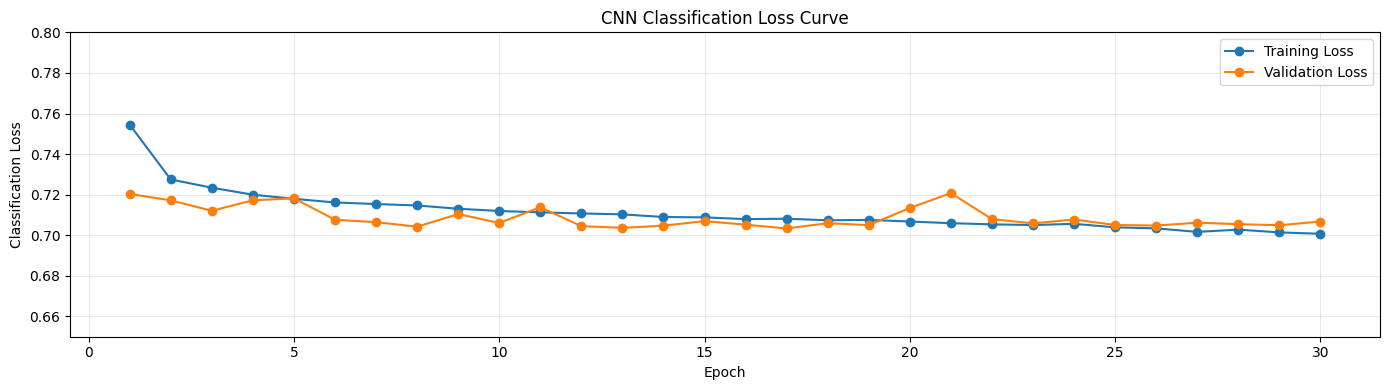

In [20]:
plt.figure(figsize=(14, 4))

epochs = range(1, num_epochs + 1)

plt.plot(
    epochs,
    train_losses,
    marker='o',
    label='Training Loss'
)

plt.plot(
    epochs,
    val_losses,
    marker='o',
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Classification Loss")
plt.title("CNN Classification Loss Curve")

# Zoom in to show the small changes more clearly
plt.ylim(0.65, 0.80)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
import matplotlib.pyplot as plt

# small overfit test
small_X = X_train_cnn[:2000]
small_y = y_train_tensor[:2000]

small_dataset = TensorDataset(small_X, small_y)
small_loader = DataLoader(small_dataset, batch_size=128, shuffle=True)

small_model = CNNClassifier().to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(small_model.parameters(), lr=0.001)

num_epochs = 30

train_losses = []

for epoch in range(num_epochs):
    small_model.train()
    train_loss = 0
    
    for X_batch, y_batch in small_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        optimizer.zero_grad()
        logits = small_model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
    
    train_loss /= len(small_loader)
    train_losses.append(train_loss)
    
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f}")

NameError: name 'CNNClassifier' is not defined

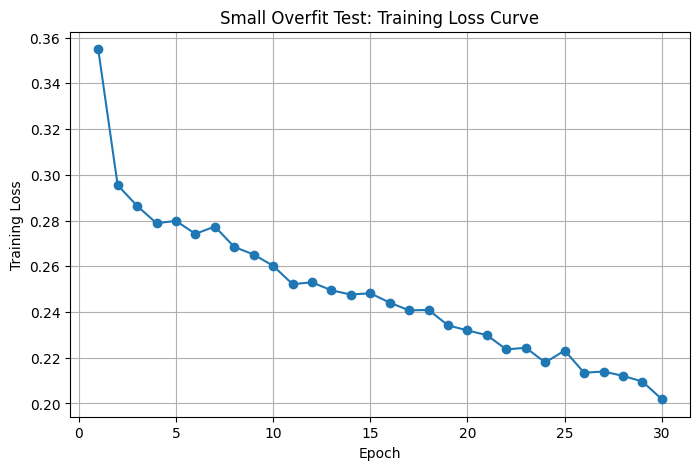

In [106]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Small Overfit Test: Training Loss Curve")
plt.grid(True)
plt.show()

In [21]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

cnn_model.eval()

all_probs = []
all_preds = []
all_true = []

with torch.no_grad():
    for X_batch, y_batch in test_loader_cnn:
        X_batch = X_batch.to(device)
        
        logits = cnn_model(X_batch)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).int()
        
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(y_batch.numpy())

print(confusion_matrix(all_true, all_preds))
print(classification_report(all_true, all_preds))
print("ROC AUC:", roc_auc_score(all_true, all_probs))

[[52765  3773]
 [ 3552  1413]]
              precision    recall  f1-score   support

         0.0       0.94      0.93      0.94     56538
         1.0       0.27      0.28      0.28      4965

    accuracy                           0.88     61503
   macro avg       0.60      0.61      0.61     61503
weighted avg       0.88      0.88      0.88     61503

ROC AUC: 0.7457560363558029


In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, roc_auc_score
)

all_true = np.array(all_true).ravel()
all_preds = np.array(all_preds).ravel()
all_probs = np.array(all_probs).ravel()

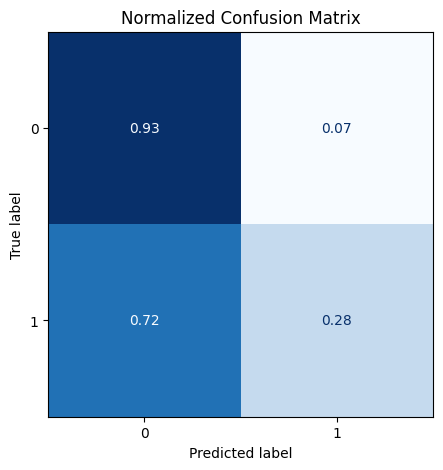

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_norm = confusion_matrix(all_true, all_preds, normalize='true')

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=[0, 1])
disp.plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)

ax.set_title("Normalized Confusion Matrix")
plt.show()

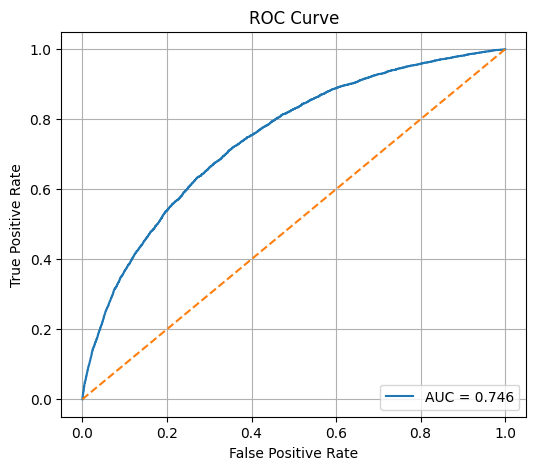

In [24]:
fpr, tpr, thresholds = roc_curve(all_true, all_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# MLP Classifier

In [25]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

In [26]:
# =========================
# Prepare data for MLP
# =========================

X_mlp = encoded_train.copy()
X_test_mlp = encoded_test.copy()

y_mlp = np.array(y_train).astype(np.float32)
y_test_mlp = np.array(y_test).astype(np.float32)

# split training data into train / validation
X_mlp_train, X_mlp_val, y_mlp_train, y_mlp_val = train_test_split(
    X_mlp,
    y_mlp,
    test_size=0.2,
    random_state=42,
    stratify=y_mlp
)

# scale encoded features
scaler_mlp = StandardScaler()

X_mlp_train = scaler_mlp.fit_transform(X_mlp_train)
X_mlp_val = scaler_mlp.transform(X_mlp_val)
X_test_mlp = scaler_mlp.transform(X_test_mlp)

# convert to tensors
X_mlp_train_tensor = torch.tensor(X_mlp_train, dtype=torch.float32)
y_mlp_train_tensor = torch.tensor(y_mlp_train, dtype=torch.float32).view(-1, 1)

X_mlp_val_tensor = torch.tensor(X_mlp_val, dtype=torch.float32)
y_mlp_val_tensor = torch.tensor(y_mlp_val, dtype=torch.float32).view(-1, 1)

X_mlp_test_tensor = torch.tensor(X_test_mlp, dtype=torch.float32)
y_mlp_test_tensor = torch.tensor(y_test_mlp, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_mlp_train_tensor, y_mlp_train_tensor)
val_dataset = TensorDataset(X_mlp_val_tensor, y_mlp_val_tensor)
test_dataset = TensorDataset(X_mlp_test_tensor, y_mlp_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

In [27]:
# =========================
# MLP classifier
# =========================

class MLPClassifier(nn.Module):
    def __init__(self, input_dim):
        super(MLPClassifier, self).__init__()
        
        self.model = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(64, 1)
        )
        
    def forward(self, x):
        return self.model(x)

In [ ]:
# =========================
# Train MLP
# =========================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

input_dim_mlp = X_mlp_train_tensor.shape[1]
mlp_model = MLPClassifier(input_dim=input_dim_mlp).to(device)

# handle class imbalance
num_pos = (y_mlp_train_tensor == 1).sum()
num_neg = (y_mlp_train_tensor == 0).sum()
pos_weight = (num_neg / num_pos).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=0.001, weight_decay=1e-4)

num_epochs = 30
best_val_auc = 0
best_model_state = None

for epoch in range(num_epochs):
    mlp_model.train()
    train_loss = 0
    
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        
        optimizer.zero_grad()
        logits = mlp_model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * batch_x.size(0)
    
    train_loss /= len(train_loader.dataset)
    
    # validation
    mlp_model.eval()
    val_probs = []
    val_true = []
    
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x = batch_x.to(device)
            
            logits = mlp_model(batch_x)
            probs = torch.sigmoid(logits).cpu().numpy()
            
            val_probs.extend(probs.ravel())
            val_true.extend(batch_y.numpy().ravel())
    
    val_auc = roc_auc_score(val_true, val_probs)
    
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_model_state = mlp_model.state_dict()
    
    print(
        f"Epoch [{epoch+1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | Val AUC: {val_auc:.4f}"
    )

print(f"\nBest Validation AUC: {best_val_auc:.4f}")

Epoch [01/30] Train Loss: 1.1448 | Val AUC: 0.7369
Epoch [02/30] Train Loss: 1.1123 | Val AUC: 0.7405
Epoch [03/30] Train Loss: 1.1057 | Val AUC: 0.7411
Epoch [04/30] Train Loss: 1.1033 | Val AUC: 0.7400
Epoch [05/30] Train Loss: 1.0970 | Val AUC: 0.7396
Epoch [06/30] Train Loss: 1.0956 | Val AUC: 0.7439
Epoch [07/30] Train Loss: 1.0934 | Val AUC: 0.7430
Epoch [08/30] Train Loss: 1.0907 | Val AUC: 0.7433
Epoch [09/30] Train Loss: 1.0901 | Val AUC: 0.7429
Epoch [10/30] Train Loss: 1.0878 | Val AUC: 0.7432
Epoch [11/30] Train Loss: 1.0876 | Val AUC: 0.7428
Epoch [12/30] Train Loss: 1.0856 | Val AUC: 0.7457
Epoch [13/30] Train Loss: 1.0828 | Val AUC: 0.7427
Epoch [14/30] Train Loss: 1.0839 | Val AUC: 0.7441
Epoch [15/30] Train Loss: 1.0830 | Val AUC: 0.7470
Epoch [16/30] Train Loss: 1.0810 | Val AUC: 0.7449
Epoch [17/30] Train Loss: 1.0807 | Val AUC: 0.7456
Epoch [18/30] Train Loss: 1.0783 | Val AUC: 0.7433
Epoch [19/30] Train Loss: 1.0763 | Val AUC: 0.7430
Epoch [20/30] Train Loss: 1.074

In [29]:
# =========================
# Test evaluation
# =========================

mlp_model.load_state_dict(best_model_state)
mlp_model.eval()

test_probs = []
test_true = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x = batch_x.to(device)
        
        logits = mlp_model(batch_x)
        probs = torch.sigmoid(logits).cpu().numpy()
        
        test_probs.extend(probs.ravel())
        test_true.extend(batch_y.numpy().ravel())

test_probs = np.array(test_probs)
test_true = np.array(test_true)

test_auc = roc_auc_score(test_true, test_probs)

print(f"Test AUC: {test_auc:.4f}")

Test AUC: 0.7495


In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# =========================
# Threshold comparison
# =========================

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for threshold in thresholds:
    pred = (test_probs >= threshold).astype(int)
    
    threshold_results.append({
        "threshold": threshold,
        "precision_1": precision_score(test_true, pred, pos_label=1),
        "recall_1": recall_score(test_true, pred, pos_label=1),
        "f1_1": f1_score(test_true, pred, pos_label=1),
        "accuracy": accuracy_score(test_true, pred)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,threshold,precision_1,recall_1,f1_1,accuracy
0,0.3,0.107191,0.915408,0.191910,0.377656
1,0.4,0.128606,0.831420,0.222756,0.531616
2,0.5,0.164285,0.673716,0.264155,0.696990
3,0.6,0.204323,0.517825,0.293025,0.798286
4,0.7,0.251654,0.344814,0.290959,0.864332


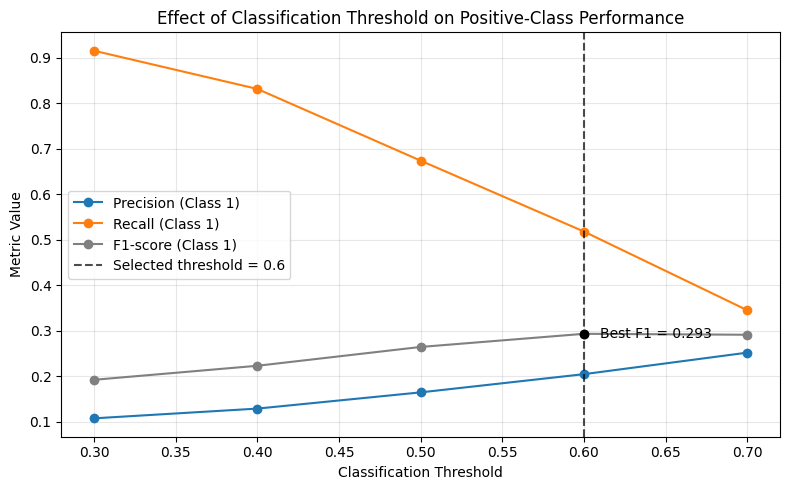

In [37]:
main_color = "#1f77b4"
accent_color = "#ff7f0e"

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["threshold"], 
    threshold_df["precision_1"], 
    marker="o", 
    label="Precision (Class 1)",
    color=main_color
)

plt.plot(
    threshold_df["threshold"], 
    threshold_df["recall_1"], 
    marker="o", 
    label="Recall (Class 1)",
    color=accent_color
)

plt.plot(
    threshold_df["threshold"], 
    threshold_df["f1_1"], 
    marker="o", 
    label="F1-score (Class 1)",
    color="gray"
)

# mark selected threshold
best_threshold = threshold_df.loc[threshold_df["f1_1"].idxmax(), "threshold"]
best_f1 = threshold_df["f1_1"].max()

plt.axvline(
    best_threshold, 
    linestyle="--", 
    color="black", 
    alpha=0.7,
    label=f"Selected threshold = {best_threshold}"
)

plt.scatter(
    best_threshold, 
    best_f1, 
    color="black", 
    zorder=5
)

plt.text(
    best_threshold + 0.01, 
    best_f1, 
    f"Best F1 = {best_f1:.3f}",
    va="center"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Metric Value")
plt.title("Effect of Classification Threshold on Positive-Class Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("plots_eda/mlp_threshold_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

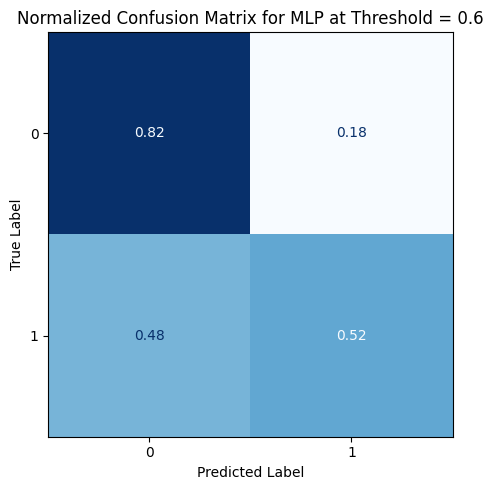

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =========================
# Normalized confusion matrix at threshold = 0.6
# =========================

threshold = 0.6
test_pred_06 = (test_probs >= threshold).astype(int)

cm_norm_06 = confusion_matrix(
    test_true,
    test_pred_06,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_norm_06,
    display_labels=[0, 1]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    colorbar=False
)

ax.set_title("Normalized Confusion Matrix for MLP at Threshold = 0.6")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()
plt.savefig("plots_eda/mlp_normalized_confusion_matrix_threshold_06.png", dpi=300, bbox_inches="tight")
plt.show()